# Bank marketing: can a subscription model support a pre-call decision?

Call prioritisation needs information available before a call begins. This project asks whether a logistic regression can identify likely term-deposit subscribers under that timing constraint. It deliberately includes completed call duration in one model, then removes duration while keeping the split, settings and other inputs identical.

**The corrected model is not ready for call prioritisation under this protocol.** At threshold 0.5, it selects no final-test positives and recalls none of the 2,540 recorded subscribers. Corrected average precision is **0.0949**, below prevalence **0.1107**, in validation. Final AP improves modestly to **0.3219** against prevalence **0.3083**, but final Brier score **0.3083** is worse than the dummy's **0.2810**. Top-20% ranking lift changes from **0.444** to **1.254** across those periods.

Removing duration corrects a known availability flaw. It leaves large drift and probability underprediction unresolved: subscription prevalence rises from **4.81%** in training to **30.83%** in final test, while the corrected model's maximum final probability is only **4.44%**. The fixed experiment is retained so those failures remain visible.

Read the evidence through audience drift, feature timing, the controlled comparison, probability and threshold failure, capacity instability, and the next decision. The technical appendix documents the evaluation settings and assumptions. Historical subscription prediction does not measure extra subscriptions caused by targeting.

## Data and scope of the decision

The project uses **41,188 records** from `bank-additional-full.csv`. The supplied dictionary describes date order from May 2008 to November 2010. Exact timestamps and customer identifiers are absent, so the evaluation uses ordered row blocks: **24,712 training**, **8,238 validation** and **8,238 final test** records. These blocks can share a date or customer.

All raw rows, exact duplicates and categorical `unknown` labels are retained. `pdays == 999` means no prior-campaign contact. The raw sentinel is preserved while the model uses a derived never-contacted flag and training-imputed recency. Customer snapshots and macroeconomic release dates remain assumptions to verify.

Dataset: [UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing), Moro, S., Rita, P., and Cortez, P. (2014), DOI [10.24432/C5K306](https://doi.org/10.24432/C5K306), CC BY 4.0. The bundled `bank-additional-names.txt` defines this variant. Related study: Moro, Cortez and Rita (2014), DOI [10.1016/j.dss.2014.03.001](https://doi.org/10.1016/j.dss.2014.03.001).

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version
import hashlib
import json
import platform
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss,
                             confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

get_ipython().run_line_magic("matplotlib", "inline")
SEED = 123
STARTED_AT = datetime.now(timezone.utc).isoformat()
STARTED_TIMER = time.perf_counter()
# ROOT locates the project; RESULTS and FIGURES hold the outputs created below.
ROOT = Path.cwd()
assert (ROOT / "data" / "bank-additional-full.csv").exists(), "Run from this project folder."
RESULTS = ROOT / "results"
FIGURES = RESULTS / "figures"
GENERATED = ROOT / ".generated"
GENERATED.mkdir(exist_ok=True)
(GENERATED / "figures").mkdir(exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
PUBLIC_EXPORTS = ['final_test_predictions.csv', 'model_metrics.csv', 'validation_predictions.csv']
PUBLIC_FIGURES = ['03_precision_recall_and_calibration.png', '05_capacity_ranking.png']


def artifact_path(name):
    # Keep the review exports public; regenerate other diagnostics locally.
    return (RESULTS if name in PUBLIC_EXPORTS else GENERATED) / name
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
# VERSIONS records the environment used to produce the measured results.
VERSIONS = {name: version(name) for name in
            ["numpy", "pandas", "scikit-learn", "matplotlib", "nbformat", "nbclient", "ipykernel"]}
display(pd.Series(VERSIONS, name="executed_version").to_frame())

def save_figure(name, caption=None):
    # Reuse FIGURES to save each chart before showing it in the notebook.
    # Reserve a footer so the exported chart carries its interpretation and limit.
    figure = plt.gcf()
    if caption:
        figure.tight_layout(rect=(0, 0.14, 1, 1))
        figure.text(0.02, 0.025, caption, fontsize=8.5, ha="left", va="bottom", linespacing=1.4)
    directory = FIGURES if name in PUBLIC_FIGURES else GENERATED / "figures"
    plt.savefig(directory / name, bbox_inches="tight", dpi=160)
    plt.show()

,executed_version
numpy,2.3.5
pandas,3.0.1
scikit-learn,1.9.1
matplotlib,3.11.2
nbformat,5.11.1
nbclient,0.11.0
ipykernel,6.29.5


In [2]:
DATA_PATH = ROOT / "data" / "bank-additional-full.csv"
# DATA_SHA256 checks that the bundled CSV matches its recorded provenance.
DATA_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
EXPECTED_SHA256 = "74adfc578bf77a7ff4bb1ba4a9f8709d9e3c6907342959c2c8416847e0afb4d8"
assert DATA_SHA256 == EXPECTED_SHA256, "Bundled data changed; inspect provenance before fitting."
raw = pd.read_csv(DATA_PATH, sep=";")
assert raw.shape == (41188, 21)
assert raw["y"].isin(["yes", "no"]).all()
assert not raw.isna().any().any()
# data adds an outcome code and original row position; raw remains unchanged.
data = raw.copy()
data["record_position"] = np.arange(len(data))
data["target"] = data["y"].eq("yes").astype(int)
assert data["record_position"].is_monotonic_increasing and len(data) == len(raw)
categorical_raw = raw.select_dtypes(include=["object", "str"]).columns
unknown_counts = raw[categorical_raw].eq("unknown").sum().sort_values(ascending=False)
# audit records missing codes, duplicates and class balance without deleting records.
audit = {
    "rows": len(raw), "columns": len(raw.columns), "missing_cells_as_null": int(raw.isna().sum().sum()),
    "exact_duplicate_rows_retained": int(raw.duplicated().sum()),
    "pdays_999_never_contacted": int(raw["pdays"].eq(999).sum()),
    "subscribers": int(data["target"].sum()), "subscription_rate": float(data["target"].mean()),
    "unknown_labels_by_column": {k: int(v) for k, v in unknown_counts.items() if v > 0},
    "sha256": DATA_SHA256, "raw_rows_deleted": 0,
    "negative_duration_rows": int(raw["duration"].lt(0).sum()),
    "negative_previous_contact_rows": int(raw["previous"].lt(0).sum()),
    "zero_duration_yes_rows": int((raw["duration"].eq(0) & raw["y"].eq("yes")).sum()),
}
assert audit["negative_duration_rows"] == audit["negative_previous_contact_rows"] == 0
(artifact_path("data_audit.json")).write_text(json.dumps(audit, indent=2), encoding="utf-8")
display(pd.Series({k: v for k, v in audit.items() if k != "unknown_labels_by_column"}, name="audit_result").to_frame())
display(unknown_counts.loc[unknown_counts > 0].rename("unknown_rows").to_frame())
display(raw["y"].value_counts().rename_axis("outcome").to_frame("records"))
display(raw[["age", "duration", "campaign", "pdays", "previous"]].describe().round(2))

,audit_result
rows,41188
columns,21
missing_cells_as_null,0
exact_duplicate_rows_retained,12
pdays_999_never_contacted,39673
subscribers,4640
subscription_rate,0.112654
sha256,74adfc578bf77a7ff4bb1ba4a9f8709d9e3c6907342959...
raw_rows_deleted,0
negative_duration_rows,0


,unknown_rows
default,8597
education,1731
housing,990
loan,990
job,330
marital,80


,records
outcome,
no,36548
yes,4640


,age,duration,campaign,pdays,previous
count,41188.00,41188.00,41188.00,41188.00,41188.00
mean,40.02,258.29,2.57,962.48,0.17
std,10.42,259.28,2.77,186.91,0.49
min,17.00,0.00,1.00,0.00,0.00
25%,32.00,102.00,1.00,999.00,0.00
50%,38.00,180.00,2.00,999.00,0.00
75%,47.00,319.00,3.00,999.00,0.00
max,98.00,4918.00,56.00,999.00,7.00


## 1. Does the history describe a stable targeting population?

The split policy is fixed before inspecting performance. The following audit shows how outcome prevalence changes through the supplied order. A prioritisation model learned from one audience needs another review if the later audience or economic context differs.

,records,first_record_position,last_record_position,subscribers,subscription_rate,pdays_999_rate,euribor3m_mean
split,,,,,,,
Training,24712,0,24711,1188,0.0481,0.9998,4.9046
Validation,8238,24712,32949,912,0.1107,0.9796,2.3621
Final test,8238,32950,41187,2540,0.3083,0.8372,1.0307


,audit_result
validation_records_exactly_matching_training,0
test_records_exactly_matching_training,0
meaning,Exact row match only; customer independence ca...


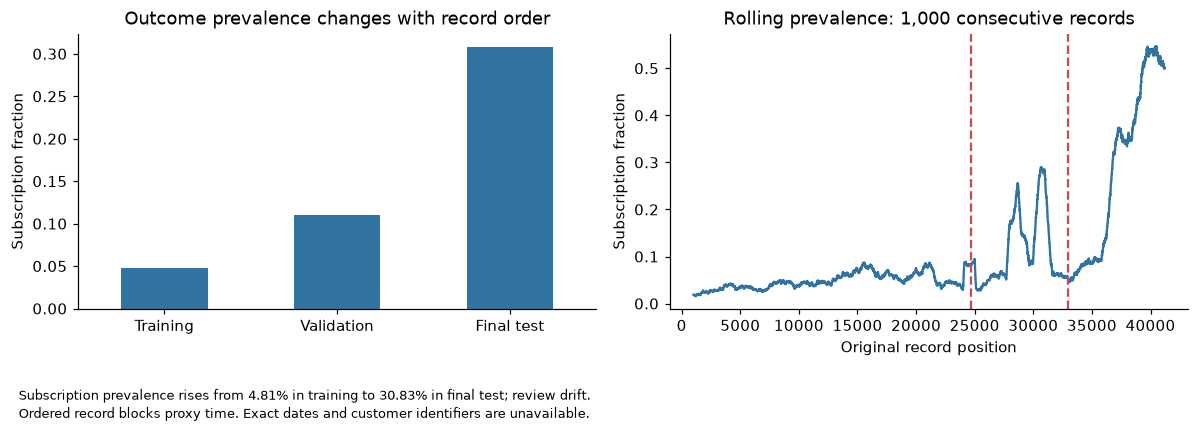

In [3]:
# blocks preserves source order while assigning disjoint training, validation and test rows.
n = len(data)
train_end, validation_end = int(0.60 * n), int(0.80 * n)
blocks = {"Training": data.iloc[:train_end].copy(),
          "Validation": data.iloc[train_end:validation_end].copy(),
          "Final test": data.iloc[validation_end:].copy()}
assert sum(len(part) for part in blocks.values()) == n
assert blocks["Training"]["record_position"].max() < blocks["Validation"]["record_position"].min()
assert blocks["Validation"]["record_position"].max() < blocks["Final test"]["record_position"].min()
split_rows = []
for name, part in blocks.items():
    split_rows.append({"split": name, "records": len(part),
        "first_record_position": int(part["record_position"].min()),
        "last_record_position": int(part["record_position"].max()),
        "subscribers": int(part["target"].sum()), "subscription_rate": float(part["target"].mean()),
        "pdays_999_rate": float(part["pdays"].eq(999).mean()),
        "euribor3m_mean": float(part["euribor3m"].mean())})
split_summary = pd.DataFrame(split_rows).set_index("split")
display(split_summary.round(4))
split_summary.to_csv(artifact_path("split_summary.csv"))

# Fingerprints detect exact row overlap; they cannot identify repeated customers.
row_fingerprints = pd.util.hash_pandas_object(raw, index=False)
train_fingerprints = set(row_fingerprints.iloc[:train_end])
duplicate_overlap = {"validation_records_exactly_matching_training": int(row_fingerprints.iloc[train_end:validation_end].isin(train_fingerprints).sum()),
                     "test_records_exactly_matching_training": int(row_fingerprints.iloc[validation_end:].isin(train_fingerprints).sum()),
                     "meaning": "Exact row match only; customer independence cannot be checked"}
(artifact_path("duplicate_split_audit.json")).write_text(json.dumps(duplicate_overlap, indent=2), encoding="utf-8")
display(pd.Series(duplicate_overlap, name="audit_result").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
# Reuse split_summary and data to show prevalence changes without changing the fixed split.
split_summary["subscription_rate"].plot.bar(ax=axes[0], color="#3274a1", rot=0)
axes[0].set(title="Outcome prevalence changes with record order", ylabel="Subscription fraction", xlabel="")
rolling_rate = data["target"].rolling(1000, min_periods=1000).mean()
axes[1].plot(data["record_position"], rolling_rate, color="#3274a1")
for boundary in [train_end, validation_end]:
    axes[1].axvline(boundary, color="#c44e52", linestyle="--")
axes[1].set(title="Rolling prevalence: 1,000 consecutive records", xlabel="Original record position", ylabel="Subscription fraction")
fig.tight_layout()
save_figure("01_class_balance_and_drift.png", 'Subscription prevalence rises from 4.81% in training to 30.83% in final test; review drift.\nOrdered record blocks proxy time. Exact dates and customer identifiers are unavailable.')

### Subscription prevalence changes substantially across the ordered blocks

The left bars compare the three fixed blocks: 4.81% subscription in training, 11.07% in validation and 30.83% in final test. The right line shows a moving prevalence over 1,000 consecutive records; dashed lines mark the row-split boundaries. The changes are visible within and across blocks.

For the call-prioritisation decision, this weakens the case for carrying training probabilities or a fixed threshold directly into later operations. Review audience and economic-context drift before expecting calibrated probabilities.

The line is a descriptive audit after the policy is fixed. Row order proxies chronology; exact dates, repeat customers and the reasons for prevalence change cannot be established from this file.

## 2. Can correcting feature timing produce useful predictions?

Completed duration is unavailable before calling. The corrected model excludes it; both models also exclude `campaign`, `contact`, `month` and `day_of_week` because their documented current-contact timing does not establish an earlier snapshot. The pair otherwise uses the same fixed logistic settings and training-only preprocessing.

Customer attributes, prior-campaign history and economic indicators are included conditionally. Their real pre-call snapshots and publication vintage have not been verified. The correction addresses demonstrated duration leakage, not every possible deployment assumption. The next cells fit the fixed pair and score the same later records without refitting.

In [4]:
CATEGORICAL = ["job", "marital", "education", "default", "housing", "loan", "poutcome"]
NUMERIC = ["age", "previous", "pdays_known", "never_previously_contacted",
           "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
EXCLUDED_CURRENT_CONTACT = ["campaign", "contact", "month", "day_of_week"]
CORRECTED = "Corrected: before-call inputs"
FLAWED = "Flawed: includes call duration"
BASELINE = "Dummy: training prevalence"

def make_features(frame, include_duration=False):
    # Build the common inputs; only the flawed model receives the duration column.
    features = frame[["age", "previous", "emp.var.rate", "cons.price.idx",
                      "cons.conf.idx", "euribor3m", "nr.employed"] + CATEGORICAL].copy()
    features["never_previously_contacted"] = frame["pdays"].eq(999).astype(int)
    features["pdays_known"] = frame["pdays"].where(frame["pdays"].ne(999), np.nan)
    if include_duration:
        features["duration"] = frame["duration"]
    return features

def logistic_pipeline(include_duration=False):
    # Fit recency imputation, scaling and category encoding inside the training pipeline.
    numeric = NUMERIC + (["duration"] if include_duration else [])
    preprocess = ColumnTransformer([
        ("numeric", Pipeline([("impute", SimpleImputer(strategy="median")),
                              ("scale", StandardScaler())]), numeric),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
    ], remainder="drop")
    return Pipeline([("preprocess", preprocess),
                     ("model", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                                                  tol=1e-6, random_state=SEED))])

# models holds the controlled pair; feature_sets uses only the earlier training block.
models = {FLAWED: logistic_pipeline(include_duration=True), CORRECTED: logistic_pipeline()}
train = blocks["Training"]
feature_sets = {name: make_features(train, include_duration=(name == FLAWED)) for name in models}
assert set(feature_sets[FLAWED].columns) - set(feature_sets[CORRECTED].columns) == {"duration"}
assert set(feature_sets[CORRECTED].columns) - set(feature_sets[FLAWED].columns) == set()
assert set(feature_sets[CORRECTED]).isdisjoint({"duration", "y", "target", "record_position", *EXCLUDED_CURRENT_CONTACT})
fit_records = []
for name, model in models.items():
    # Fit each pipeline once and retain convergence evidence in fit_records.
    started = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(feature_sets[name], train["target"])
    convergence_warnings = [str(item.message) for item in caught if issubclass(item.category, ConvergenceWarning)]
    assert not convergence_warnings, f"{name} did not converge: {convergence_warnings}"
    fit_records.append({"model": name, "training_records": len(train),
        "solver_iterations": int(model["model"].n_iter_.max()), "convergence_warnings": len(convergence_warnings),
        "fit_seconds": round(time.perf_counter() - started, 3),
        "regularisation_C": 1.0, "class_weight": "None", "solver": "lbfgs"})

# dummy learns training prevalence and later scores each block without refitting.
dummy = DummyClassifier(strategy="prior")
dummy.fit(np.zeros((len(train), 1)), train["target"])
fit_summary = pd.DataFrame(fit_records)
fit_summary.to_csv(artifact_path("fit_summary.csv"), index=False)
display(fit_summary)

# Compare later categories with train to expose how the fitted encoder handles new labels.
encoding_audit = []
for name, part in blocks.items():
    for column in CATEGORICAL:
        unseen = ~part[column].isin(train[column].unique())
        encoding_audit.append({"split": name, "column": column,
            "unknown_label_records": int(part[column].eq("unknown").sum()),
            "unseen_training_category_records": int(unseen.sum())})
encoding_table = pd.DataFrame(encoding_audit)
encoding_table.to_csv(artifact_path("category_audit.csv"), index=False)
display(encoding_table.loc[encoding_table["unseen_training_category_records"] > 0])

,model,training_records,solver_iterations,convergence_warnings,fit_seconds,regularisation_C,class_weight,solver
0,Flawed: includes call duration,24712,196,0,0.792,1.0,None,lbfgs
1,Corrected: before-call inputs,24712,257,0,1.041,1.0,None,lbfgs


,split,column,unknown_label_records,unseen_training_category_records


In [5]:
def score_metrics(actual, probability, threshold=0.5):
    # Convert probabilities at the fixed threshold, then return ranking and count metrics.
    actual, probability = np.asarray(actual), np.asarray(probability)
    predicted = probability >= threshold
    tn, fp, fn, tp = confusion_matrix(actual, predicted, labels=[0, 1]).ravel()
    return {"records": len(actual), "positive_prevalence": float(actual.mean()),
        "threshold": threshold, "accuracy": float(accuracy_score(actual, predicted)),
        "precision": float(precision_score(actual, predicted, zero_division=0)),
        "recall": float(recall_score(actual, predicted, zero_division=0)),
        "f1": float(f1_score(actual, predicted, zero_division=0)),
        "average_precision": float(average_precision_score(actual, probability)),
        "brier_score": float(brier_score_loss(actual, probability)),
        "predicted_positive_records": int(predicted.sum()), "true_negatives": int(tn),
        "false_positives": int(fp), "false_negatives": int(fn), "true_positives": int(tp)}

# prediction_blocks stores row probabilities; metric_rows summarises the same rows.
prediction_blocks, metric_rows = {}, []
for split, part in blocks.items():
    predicted = pd.DataFrame({"record_position": part["record_position"].to_numpy(),
                              "actual_subscription": part["target"].to_numpy()})
    for name, model in models.items():
        # Reuse the training-fitted model for later blocks; predict_proba never refits it.
        probability = model.predict_proba(make_features(part, include_duration=(name == FLAWED)))[:, 1]
        predicted[name] = probability
        metric_rows.append({"split": split, "model": name, **score_metrics(part["target"], probability)})
    probability = dummy.predict_proba(np.zeros((len(part), 1)))[:, 1]
    predicted[BASELINE] = probability
    metric_rows.append({"split": split, "model": BASELINE, **score_metrics(part["target"], probability)})
    prediction_blocks[split] = predicted
    predicted.to_csv(artifact_path(split.lower().replace(" ", "_") + "_predictions.csv"), index=False)

# metrics combines the block scores; test_metrics and val_metrics support later interpretation.
metrics = pd.DataFrame(metric_rows)
metrics.to_csv(artifact_path("model_metrics.csv"), index=False)
(artifact_path("model_metrics.json")).write_text(json.dumps(metric_rows, indent=2), encoding="utf-8")
report_columns = ["accuracy", "precision", "recall", "average_precision", "f1", "brier_score",
                  "predicted_positive_records", "records"]
display(metrics.set_index(["split", "model"])[report_columns].round(4))
test_metrics = metrics.loc[metrics["split"].eq("Final test")].set_index("model")
val_metrics = metrics.loc[metrics["split"].eq("Validation")].set_index("model")
assert np.isclose(test_metrics.loc[BASELINE, "average_precision"], test_metrics.loc[BASELINE, "positive_prevalence"])

accuracy  precision  recall  \
split      model                                                         
Training   Flawed: includes call duration    0.9580     0.6206  0.3249   
           Corrected: before-call inputs     0.9525     0.6182  0.0286   
           Dummy: training prevalence        0.9519     0.0000  0.0000   
Validation Flawed: includes call duration    0.8897     0.5246  0.0351   
           Corrected: before-call inputs     0.8893     0.0000  0.0000   
           Dummy: training prevalence        0.8893     0.0000  0.0000   
Final test Flawed: includes call duration    0.6917     0.0000  0.0000   
           Corrected: before-call inputs     0.6917     0.0000  0.0000   
           Dummy: training prevalence        0.6917     0.0000  0.0000   

                                           average_precision      f1  \
split      model                                                       
Training   Flawed: includes call duration             0.5309  0.4265   
           Corrected: before-call inputs              0.1032  0.0547   
           Dummy: training prevalence                 0.0481  0.0000   
Validation Flawed: includes call duration             0.1779  0.0658   
           Corrected: before-call inputs              0.0949  0.0000   
           Dummy: training prevalence                 0.1107  0.0000   
Final test Flawed: includes call duration             0.3962  0.0000   
           Corrected: before-call inputs              0.3219  0.0000   
           Dummy: training prevalence                 0.3083  0.0000   

                                           brier_score  \
split      model                                         
Training   Flawed: includes call duration       0.0311   
           Corrected: before-call inputs        0.0446   
           Dummy: training prevalence           0.0458   
Validation Flawed: includes call duration       0.1061   
           Corrected: before-call inputs        0.1100   
           Dummy: training prevalence           0.1024   
Final test Flawed: includes call duration       0.3083   
           Corrected: before-call inputs        0.3083   
           Dummy: training prevalence           0.2810   

                                           predicted_positive_records  records  
split      model                                                                
Training   Flawed: includes call duration                         622    24712  
           Corrected: before-call inputs                           55    24712  
           Dummy: training prevalence                               0    24712  
Validation Flawed: includes call duration                          61     8238  
           Corrected: before-call inputs                            0     8238  
           Dummy: training prevalence                               0     8238  
Final test Flawed: includes call duration                           0     8238  
           Corrected: before-call inputs                            0     8238  
           Dummy: training prevalence                               0     8238

**Final test comparison:** flawed average precision is **0.3962**; corrected average precision is **0.3219**. The duration model's AP difference is **+0.0742**, on identical 8,238 records. At threshold 0.5, corrected precision is 0.000, recall is 0.000, and accuracy is 0.692. The flawed score cannot justify a pre-call decision because duration would not yet exist.

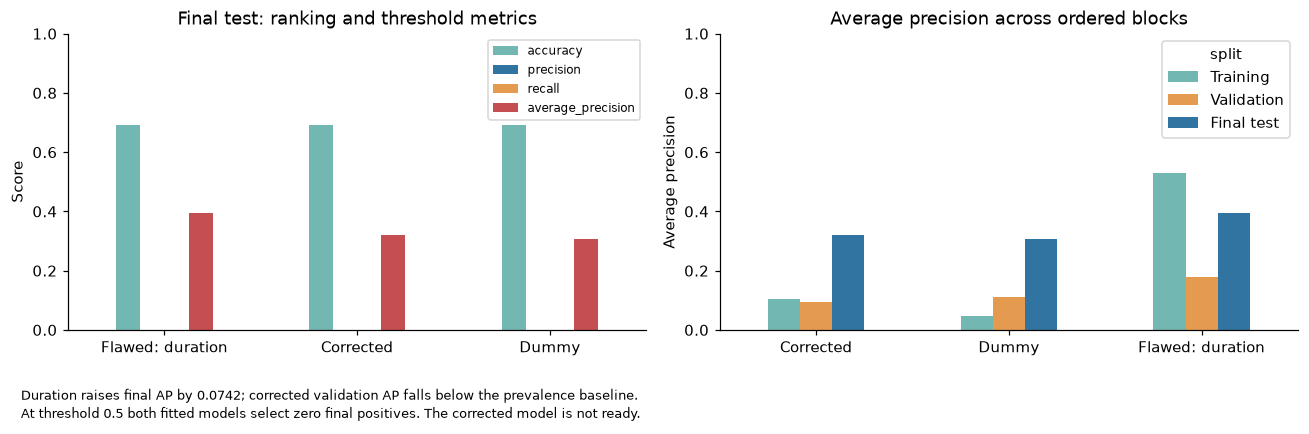

In [6]:
# Reuse the identical final rows to compare AP and fixed-threshold performance.
flawed_test, corrected_test = test_metrics.loc[FLAWED], test_metrics.loc[CORRECTED]
ap_difference = float(flawed_test["average_precision"] - corrected_test["average_precision"])
display(Markdown(
    f"**Final test comparison:** flawed average precision is **{flawed_test['average_precision']:.4f}**; "
    f"corrected average precision is **{corrected_test['average_precision']:.4f}**. The duration model's AP "
    f"difference is **{ap_difference:+.4f}**, on identical {int(corrected_test['records']):,} records. "
    f"At threshold 0.5, corrected precision is {corrected_test['precision']:.3f}, recall is "
    f"{corrected_test['recall']:.3f}, and accuracy is {corrected_test['accuracy']:.3f}. "
    "The flawed score cannot justify a pre-call decision because duration would not yet exist."
))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
short_names = {FLAWED: "Flawed: duration", CORRECTED: "Corrected", BASELINE: "Dummy"}
plot_table = test_metrics[["accuracy", "precision", "recall", "average_precision"]].rename(index=short_names)
plot_table.plot.bar(ax=axes[0], rot=0, color=["#72b7b2", "#3274a1", "#e49b50", "#c44e52"])
axes[0].set(title="Final test: ranking and threshold metrics", ylabel="Score", xlabel="", ylim=(0, 1))
axes[0].legend(fontsize=8, loc="upper right")
drift_table = metrics.pivot(index="model", columns="split", values="average_precision").rename(index=short_names)
drift_table[["Training", "Validation", "Final test"]].plot.bar(ax=axes[1], rot=0,
                                                         color=["#72b7b2", "#e49b50", "#3274a1"])
axes[1].set(title="Average precision across ordered blocks", ylabel="Average precision", xlabel="", ylim=(0, 1))
fig.tight_layout()
save_figure("02_model_comparison.png", 'Duration raises final AP by 0.0742; corrected validation AP falls below the prevalence baseline.\nAt threshold 0.5 both fitted models select zero final positives. The corrected model is not ready.')

### The duration advantage does not make the corrected model useful

The left panel separates final accuracy, precision, recall and AP. Both fitted models have accuracy 0.6917 and zero precision/recall at 0.5 because neither selects a positive. The flawed model's AP is 0.3962 versus 0.3219 after correction. The right panel compares AP across blocks: corrected validation AP 0.0949 is below its prevalence baseline 0.1107, while final AP 0.3219 is modestly above 0.3083.

For model review, duration creates a 0.0742 final AP advantage from information unavailable before calling. Removing it is necessary, but the cross-period ranking failure and zero threshold recall prevent an operational recommendation.

Accuracy is dominated by the negative class and cannot establish subscriber detection. The pair has fixed settings and identical evaluation records; the final outcome is reported without searching for a more attractive threshold or model.

## 3. Do the probabilities and threshold support a call decision?

Ranking and probability accuracy answer different questions. A modest AP gain can coexist with probabilities that are far too low. Review both before treating a score as a subscription likelihood or adopting a call threshold.

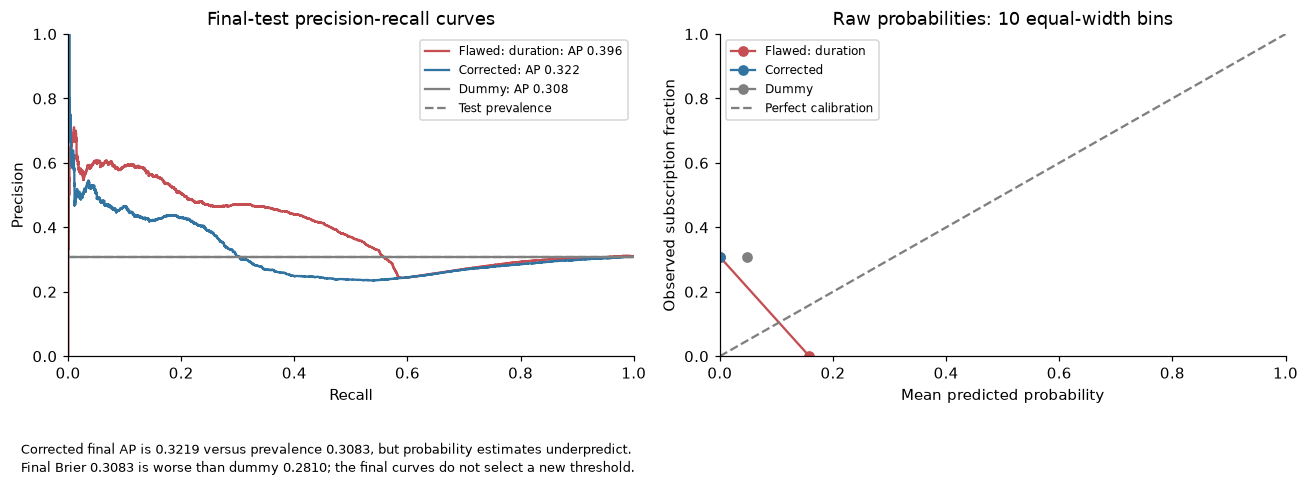

In [7]:
# test_predictions reuses saved probabilities; actual supplies their matched test outcomes.
test_predictions = prediction_blocks["Final test"]
actual = test_predictions["actual_subscription"].to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
colours = {FLAWED: "#c44e52", CORRECTED: "#3274a1", BASELINE: "#7f7f7f"}
calibration_rows = []
for name in [FLAWED, CORRECTED, BASELINE]:
    # Reuse each probability column for the PR curve and the same calibration bins.
    probability = test_predictions[name].to_numpy()
    precision_values, recall_values, _ = precision_recall_curve(actual, probability)
    axes[0].step(recall_values, precision_values, where="post", color=colours[name],
                 label=f"{short_names[name]}: AP {test_metrics.loc[name, 'average_precision']:.3f}")
    fraction_positive, mean_probability = calibration_curve(actual, probability, n_bins=10, strategy="uniform")
    axes[1].plot(mean_probability, fraction_positive, marker="o", color=colours[name], label=short_names[name])
    # Match calibration_curve's exact boundary assignment for plotted bins.
    bin_number = np.searchsorted(np.linspace(0, 1, 11)[1:-1], probability)
    for bin_id in range(10):
        mask = bin_number == bin_id
        if mask.any():
            calibration_rows.append({"model": name, "bin": bin_id,
                "probability_lower": bin_id / 10, "probability_upper": (bin_id + 1) / 10,
                "records": int(mask.sum()), "mean_probability": float(probability[mask].mean()),
                "subscription_fraction": float(actual[mask].mean())})
axes[0].axhline(actual.mean(), color="#7f7f7f", linestyle="--", label="Test prevalence")
axes[0].set(title="Final-test precision-recall curves", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1))
axes[0].legend(fontsize=8)
axes[1].plot([0, 1], [0, 1], color="#7f7f7f", linestyle="--", label="Perfect calibration")
axes[1].set(title="Raw probabilities: 10 equal-width bins", xlabel="Mean predicted probability", ylabel="Observed subscription fraction",
            xlim=(0, 1), ylim=(0, 1))
axes[1].legend(fontsize=8)
fig.tight_layout()
save_figure("03_precision_recall_and_calibration.png", 'Corrected final AP is 0.3219 versus prevalence 0.3083, but probability estimates underpredict.\nFinal Brier 0.3083 is worse than dummy 0.2810; the final curves do not select a new threshold.')

### A small final ranking gain coexists with severe probability underprediction

The left panel shows step-shaped precision-recall curves with the final prevalence reference. Corrected AP is 0.3219 against prevalence 0.3083. The right panel compares mean predicted probability with observed subscription fraction in ten equal-width bins. The corrected model's maximum final probability is 4.44%, while 30.83% of final records subscribe; Brier score is 0.3083 versus 0.2810 for the constant training-prevalence dummy.

The corrected probabilities cannot be treated as reliable subscription likelihoods in this later block. Diagnose shift and verify feature snapshots with fresh forward data before choosing recalibration or a new threshold.

These are raw fitted probabilities. Bin counts, exported to `.generated/calibration_bins.csv`, help identify sparse bins. Final curves diagnose the frozen experiment and do not select a threshold or fit a calibration model.

In [8]:
calibration_table = pd.DataFrame(calibration_rows)
calibration_table.to_csv(artifact_path("calibration_bins.csv"), index=False)
display(calibration_table.round(4))

,model,bin,probability_lower,probability_upper,records,mean_probability,subscription_fraction
0,Flawed: includes call duration,0,0.0,0.1,8237,0.0000,0.3084
1,Flawed: includes call duration,1,0.1,0.2,1,0.1582,0.0000
2,Corrected: before-call inputs,0,0.0,0.1,8238,0.0000,0.3083
3,Dummy: training prevalence,0,0.0,0.1,8238,0.0481,0.3083


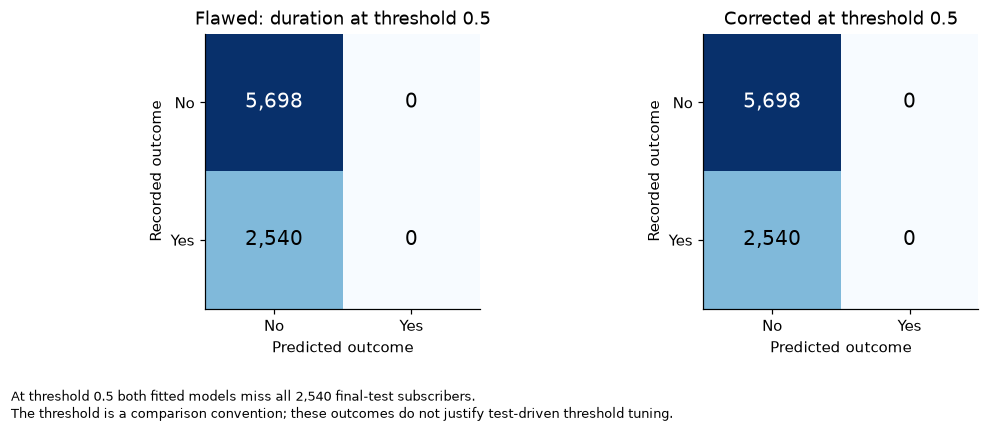

In [9]:
# Reuse actual and the model probabilities to show confusion counts at threshold 0.5.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, [FLAWED, CORRECTED]):
    matrix = confusion_matrix(actual, test_predictions[name].to_numpy() >= 0.5, labels=[0, 1])
    ax.imshow(matrix, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{matrix[i, j]:,}", ha="center", va="center",
                    color="white" if matrix[i, j] > matrix.max() / 2 else "black", fontsize=13)
    ax.set(title=f"{short_names[name]} at threshold 0.5", xlabel="Predicted outcome", ylabel="Recorded outcome",
           xticks=[0, 1], xticklabels=["No", "Yes"], yticks=[0, 1], yticklabels=["No", "Yes"])
fig.tight_layout()
save_figure("04_confusion_matrices.png", 'At threshold 0.5 both fitted models miss all 2,540 final-test subscribers.\nThe threshold is a comparison convention; these outcomes do not justify test-driven threshold tuning.')

### The fixed 0.5 rule misses every final-test subscriber

The left confusion matrix is the flawed duration model and the right is the corrected model. Both put all 8,238 final records in the predicted-No column: 5,698 recorded non-subscribers are correct, but all 2,540 recorded subscribers are missed. Recall is zero.

A call rule based on the current 0.5 output would identify no subscribers for prioritisation. The accuracy of 69.17% conceals this failure, so the decision must include recall and the outcome counts.

The threshold is an explicit comparison convention, not an agreed economic optimum. This failure does not authorise tuning against the final outcomes. Error costs, consent rules and a viable current contact policy are not supplied.

## 4. Would a ranking-only capacity rule be more stable?

The next illustration ranks 20% of each block by score, avoiding a fixed probability threshold. It tests ranking stability, not an approved capacity target. The same split's prevalence supplies the lift reference.

illustrative_capacity_fraction  \
split      model                                                            
Validation Flawed: includes call duration                             0.2   
           Corrected: before-call inputs                              0.2   
Final test Flawed: includes call duration                             0.2   
           Corrected: before-call inputs                              0.2   

                                           records_scored  records_selected  \
split      model                                                              
Validation Flawed: includes call duration            8238              1648   
           Corrected: before-call inputs             8238              1648   
Final test Flawed: includes call duration            8238              1648   
           Corrected: before-call inputs             8238              1648   

                                           actual_selected_fraction  \
split      model                                                      
Validation Flawed: includes call duration                       0.2   
           Corrected: before-call inputs                        0.2   
Final test Flawed: includes call duration                       0.2   
           Corrected: before-call inputs                        0.2   

                                           recorded_subscribers_selected  \
split      model                                                           
Validation Flawed: includes call duration                            151   
           Corrected: before-call inputs                              81   
Final test Flawed: includes call duration                            776   
           Corrected: before-call inputs                             637   

                                           precision_at_20pct  \
split      model                                                
Validation Flawed: includes call duration              0.0916   
           Corrected: before-call inputs               0.0492   
Final test Flawed: includes call duration              0.4709   
           Corrected: before-call inputs               0.3865   

                                           recall_at_20pct  \
split      model                                             
Validation Flawed: includes call duration           0.1656   
           Corrected: before-call inputs            0.0888   
Final test Flawed: includes call duration           0.3055   
           Corrected: before-call inputs            0.2508   

                                           same_split_prevalence  \
split      model                                                   
Validation Flawed: includes call duration                 0.1107   
           Corrected: before-call inputs                  0.1107   
Final test Flawed: includes call duration                 0.3083   
           Corrected: before-call inputs                  0.3083   

                                           ranking_lift_vs_split_prevalence  
split      model                                                             
Validation Flawed: includes call duration                            0.8276  
           Corrected: before-call inputs                             0.4440  
Final test Flawed: includes call duration                            1.5272  
           Corrected: before-call inputs                             1.2536

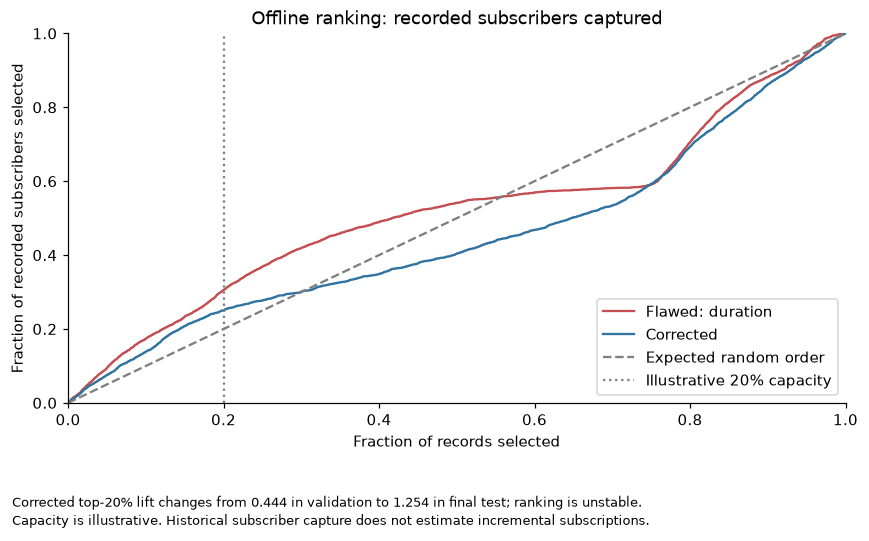

In [10]:
# CAPACITY_FRACTION is illustrative; capacity_rows keeps validation and test comparisons.
CAPACITY_FRACTION = 0.20
capacity_rows = []
for split in ["Validation", "Final test"]:
    predicted = prediction_blocks[split]
    labels = predicted["actual_subscription"].to_numpy()
    positions = predicted["record_position"].to_numpy()
    count = int(np.ceil(CAPACITY_FRACTION * len(predicted)))
    for name in [FLAWED, CORRECTED]:
        # Rank scores without labels; inspect labels only after selecting the top records.
        probability = predicted[name].to_numpy()
        ranked = np.lexsort((positions, -probability))
        selected = ranked[:count]
        captured = int(labels[selected].sum())
        precision_at_capacity = float(labels[selected].mean())
        recall_at_capacity = float(captured / labels.sum())
        capacity_rows.append({"split": split, "model": name, "illustrative_capacity_fraction": CAPACITY_FRACTION,
            "records_scored": len(predicted), "records_selected": count,
            "actual_selected_fraction": count / len(predicted), "recorded_subscribers_selected": captured,
            "precision_at_20pct": precision_at_capacity, "recall_at_20pct": recall_at_capacity,
            "same_split_prevalence": float(labels.mean()),
            "ranking_lift_vs_split_prevalence": float(precision_at_capacity / labels.mean())})
        assert len(set(selected)) == count
capacity_metrics = pd.DataFrame(capacity_rows)
capacity_metrics.to_csv(artifact_path("capacity_metrics.csv"), index=False)
display(capacity_metrics.set_index(["split", "model"]).round(4))

# Reuse test_predictions to show subscriber capture across possible capacity fractions.
fig, ax = plt.subplots(figsize=(8, 5))
for name in [FLAWED, CORRECTED]:
    ranked = np.lexsort((test_predictions["record_position"].to_numpy(), -test_predictions[name].to_numpy()))
    fraction_scored = np.arange(1, len(actual) + 1) / len(actual)
    subscriber_capture = np.cumsum(actual[ranked]) / actual.sum()
    ax.plot(fraction_scored, subscriber_capture, label=short_names[name], color=colours[name])
ax.plot([0, 1], [0, 1], color="#7f7f7f", linestyle="--", label="Expected random order")
ax.axvline(CAPACITY_FRACTION, color="#7f7f7f", linestyle=":", label="Illustrative 20% capacity")
ax.set(title="Offline ranking: recorded subscribers captured", xlabel="Fraction of records selected",
       ylabel="Fraction of recorded subscribers selected", xlim=(0, 1), ylim=(0, 1))
ax.legend()
save_figure("05_capacity_ranking.png", 'Corrected top-20% lift changes from 0.444 in validation to 1.254 in final test; ranking is unstable.\nCapacity is illustrative. Historical subscriber capture does not estimate incremental subscriptions.')

### The final ranking gain does not persist in validation

The final-test capture curves show the share of recorded subscribers found as more records are selected. The vertical line marks illustrative 20% capacity. The corrected final set contains 637 recorded subscribers among 1,648 selected records: precision 0.3865, recall 0.2508 and lift 1.254. The validation table above shows only 81 subscribers in the same-sized set, with lift 0.444.

Replacing a threshold with ranking does not resolve the instability. A modest final capture gain conflicts with validation, so review drift and evaluate current forward data before proposing a prioritisation pilot.

Twenty percent is illustrative, with deterministic row-order tie handling. The offline block assumes records can be scored as a batch. Historical capture does not estimate extra subscriptions caused by calling, saved call costs or ROI.

## 5. Why must duration stay excluded even when it raises a score?

The source dictionary states that completed call duration is unknown before the call. The next training-data graph makes the association visible, while the model-coefficient table supports review of the fitted input dependence. Neither makes duration available for the decision.

,model,transformed_feature,coefficient,absolute_coefficient
9,Flawed: includes call duration,numeric__duration,1.4231,1.4231


,model,transformed_feature,coefficient,absolute_coefficient
50,Corrected: before-call inputs,numeric__emp.var.rate,-0.7356,0.7356
70,Corrected: before-call inputs,categorical__marital_unknown,0.7091,0.7091
53,Corrected: before-call inputs,numeric__euribor3m,0.6025,0.6025
58,Corrected: before-call inputs,categorical__job_housemaid,-0.4718,0.4718
54,Corrected: before-call inputs,numeric__nr.employed,0.3439,0.3439
60,Corrected: before-call inputs,categorical__job_retired,0.3215,0.3215
63,Corrected: before-call inputs,categorical__job_student,0.3137,0.3137
75,Corrected: before-call inputs,categorical__education_illiterate,-0.2940,0.2940
67,Corrected: before-call inputs,categorical__marital_divorced,-0.2610,0.2610
65,Corrected: before-call inputs,categorical__job_unemployed,-0.2378,0.2378


,records,median_seconds,mean_seconds
y,,,
no,23524,164.0,222.49
yes,1188,786.5,864.76


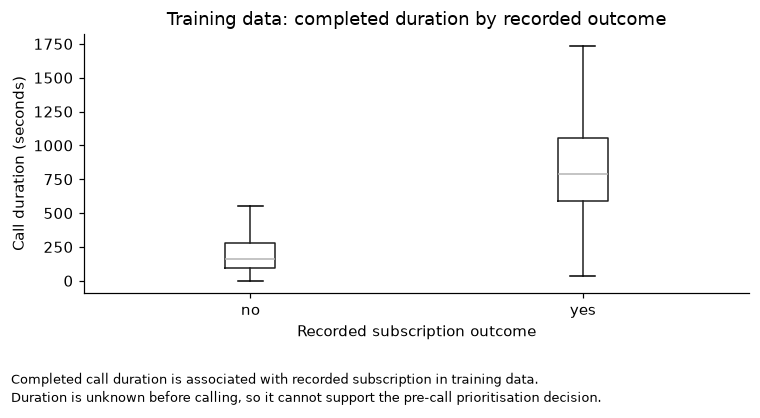

In [11]:
# Reuse both fitted pipelines to map transformed input names to logistic coefficients.
coefficient_tables = []
for name, model in models.items():
    table = pd.DataFrame({"model": name,
        "transformed_feature": model["preprocess"].get_feature_names_out(),
        "coefficient": model["model"].coef_[0]})
    table["absolute_coefficient"] = table["coefficient"].abs()
    coefficient_tables.append(table)
coefficients = pd.concat(coefficient_tables, ignore_index=True)
coefficients.to_csv(artifact_path("logistic_coefficients.csv"), index=False)
display(coefficients.loc[coefficients["transformed_feature"].str.endswith("duration")].round(4))
display(coefficients.loc[coefficients["model"].eq(CORRECTED)].sort_values("absolute_coefficient", ascending=False).head(12).round(4))

# duration_summary reviews completed-call information in training data only.
duration_summary = train.groupby("y")["duration"].agg(records="size", median_seconds="median", mean_seconds="mean")
display(duration_summary.round(2))
fig, ax = plt.subplots(figsize=(7, 4))
train.boxplot(column="duration", by="y", ax=ax, showfliers=False, grid=False)
ax.set(title="Training data: completed duration by recorded outcome", xlabel="Recorded subscription outcome", ylabel="Call duration (seconds)")
fig.suptitle("")
save_figure("06_duration_review.png", 'Completed call duration is associated with recorded subscription in training data.\nDuration is unknown before calling, so it cannot support the pre-call prioritisation decision.')

### Completed duration describes the event being predicted

The boxes compare completed call duration for recorded No and Yes outcomes in training. The medians and middle ranges differ, consistent with the duration model's predictive advantage. The coefficient export above records that fitted association under scaling and regularisation.

Exclude duration from a pre-call model regardless of whether it improves retrospective accuracy or AP. Feature usefulness must be assessed against the decision time, not just the score.

The plot hides fliers for readability; all raw records remain in fitting. Association does not prove a causal benefit from making calls longer. Correlated macroeconomic inputs also limit causal readings of logistic coefficients.

## 6. Recommended next decision

Keep the corrected model out of operational call prioritisation under this protocol. Duration removal repairs one timing flaw, but validation ranking below baseline, final Brier worse than dummy, zero recall at 0.5 and the capacity-lift reversal remain unresolved. The following calculated verdict retains those measured failures.

Verify pre-call customer snapshots and economic release vintages, define a current eligible population and outcome window, and evaluate on later customer-separated records. Review calibration and subgroup errors before agreeing capacity and error costs. Only after fresh forward evidence should a new threshold or recalibration be selected.

This dataset supplies no current consent policy, call cost, revenue, approved capacity or fairness acceptance criterion. An experiment or another credible causal design is needed to measure subscriptions attributable to targeting. The current work supports analysis review and correction, not a commercial-benefit claim.

In [12]:
# Reuse validation/test scores and capacity_metrics to describe drift and model failure.
corrected_capacity = capacity_metrics.loc[(capacity_metrics["split"] == "Final test") &
                                         (capacity_metrics["model"] == CORRECTED)].iloc[0]
corrected_validation_capacity = capacity_metrics.loc[(capacity_metrics["split"] == "Validation") &
                                                    (capacity_metrics["model"] == CORRECTED)].iloc[0]
corrected_validation = val_metrics.loc[CORRECTED]
dummy_validation_ap = float(val_metrics.loc[BASELINE, "average_precision"])
dummy_ap = float(test_metrics.loc[BASELINE, "average_precision"])
dummy_brier = float(test_metrics.loc[BASELINE, "brier_score"])
max_corrected_probability = float(test_predictions[CORRECTED].max())
recommendation = (
    "Removing duration corrects a known timing flaw, but this fitted model is not ready for operational call prioritisation. "
    f"Corrected AP is {corrected_validation['average_precision']:.4f} against prevalence {dummy_validation_ap:.4f} "
    f"in validation, and {corrected_test['average_precision']:.4f} against {dummy_ap:.4f} in final test. "
    f"Illustrative top-20% ranking lift changes from {corrected_validation_capacity['ranking_lift_vs_split_prevalence']:.3f} "
    f"to {corrected_capacity['ranking_lift_vs_split_prevalence']:.3f}. At threshold 0.5 it selects "
    f"{int(corrected_test['predicted_positive_records'])} final-test positives, with recall {corrected_test['recall']:.3f}. "
    f"Final Brier score is {corrected_test['brier_score']:.4f}, versus {dummy_brier:.4f} for the dummy. "
    f"Subscription prevalence rises from {train['target'].mean():.2%} in training to {actual.mean():.2%} in final test, "
    f"while the maximum corrected final probability is {max_corrected_probability:.2%}. "
    "Study drift and verify input snapshots and economic-data vintages using fresh forward data before selecting a new threshold or recalibrating."
)
display(Markdown(
    f"**Measured interpretation:** {recommendation}\n\nAt illustrative 20% capacity in final test, "
    f"{int(corrected_capacity['records_selected']):,} records are selected; "
    f"{int(corrected_capacity['recorded_subscribers_selected']):,} have recorded subscriptions. "
    f"Precision@20% is {corrected_capacity['precision_at_20pct']:.3f}, recall@20% is "
    f"{corrected_capacity['recall_at_20pct']:.3f}, and ranking lift against same-test prevalence is "
    f"{corrected_capacity['ranking_lift_vs_split_prevalence']:.2f}. These are historical selection statistics."
))

**Measured interpretation:** Removing duration corrects a known timing flaw, but this fitted model is not ready for operational call prioritisation. Corrected AP is 0.0949 against prevalence 0.1107 in validation, and 0.3219 against 0.3083 in final test. Illustrative top-20% ranking lift changes from 0.444 to 1.254. At threshold 0.5 it selects 0 final-test positives, with recall 0.000. Final Brier score is 0.3083, versus 0.2810 for the dummy. Subscription prevalence rises from 4.81% in training to 30.83% in final test, while the maximum corrected final probability is 4.44%. Study drift and verify input snapshots and economic-data vintages using fresh forward data before selecting a new threshold or recalibrating.

At illustrative 20% capacity in final test, 1,648 records are selected; 637 have recorded subscriptions. Precision@20% is 0.387, recall@20% is 0.251, and ranking lift against same-test prevalence is 1.25. These are historical selection statistics.

## Technical appendix: controlled comparison and assumptions

### Fixed review contract

| Item | Predeclared choice |
|---|---|
| Prediction time | Immediately before an eligible outbound call, using historical customer snapshots |
| Grain | One recorded marketing example; unique-customer grain cannot be established |
| Target | `y == "yes"`, a recorded term-deposit subscription |
| Split | Original row order: first 60% training, next 20% validation, last 20% final test |
| Model pair | Same fixed logistic regression settings; feature difference is only `duration` |
| Preprocessing | Numeric median imputation and scaling; categorical encoding; fitted on training only |
| Main threshold | 0.5, an explicit comparison convention, not a business-optimal policy |
| Main measures | Accuracy, precision, recall, average precision; also F1, Brier score and confusion counts |
| Capacity example | Rank the top 20% of each evaluation split; illustrative capacity, not an agreed target |
| Model changes | No test-driven feature changes, threshold search, hyperparameter tuning or refitting |

The validation block is an intermediate drift and performance check. Neither its outcomes nor the final test outcomes are used to tune this controlled experiment. Both models remain fitted only on the first 60%. Keeping settings fixed isolates the effect of including duration under this particular model and period.

Accuracy can reward predicting the majority class. Precision describes how often a positive classification is correct, while recall describes how many recorded subscribers it captures. Average precision summarises the precision-recall ranking without fixing a threshold. These metrics answer different questions; none is a measured financial benefit.

### Raw codes, duplication and population

`unknown` is an explicit missing-information label in categorical columns. It is retained as a category. `pdays == 999` means no previous campaign contact, rather than 999 elapsed days. The raw file retains every record. A derived feature separates the never-contacted indicator from observed recency, and the training pipeline imputes recency only for the derived numeric representation.

Exact duplicate records are counted and retained because the file lacks the identifiers needed to determine whether they are erroneous duplicates or separate events with identical attributes. Repeated customers across split blocks remain a limitation even if exact duplicate counts are small.

### Full feature timing audit

| Feature group | Availability decision |
|---|---|
| `duration` | Exclude from corrected model: target call duration is unavailable before the call |
| `campaign` | Exclude from both: count includes the current contact and the dataset does not provide an earlier snapshot |
| `contact`, `month`, `day_of_week` | Exclude from both: dictionary describes the last current-campaign contact; a known planned-call schedule could be used in a separate documented design |
| `age`, `job`, `marital`, `education`, `default`, `housing`, `loan` | Include under the assumption that customer attributes are available as a pre-call snapshot |
| `previous`, `pdays`, `poutcome` | Include under the assumption that previous-campaign history is recorded before this call |
| Macroeconomic indicators | Include conditionally: historical release timing and vintage are not supplied, so their actual pre-call availability remains unverified |
| `y`, `target`, `record_position` | Exclude: outcome is the label; row position defines evaluation order rather than a customer predictor |

The controlled pair differs only by duration. Both omit the other ambiguous current-contact fields. Removing duration corrects the demonstrated leakage. It does not prove that every retained variable was deployable at the historical decision time. Macroeconomic indicators published daily, monthly or quarterly may have a release delay or later revisions.

Demographic and financial attributes may also raise fairness questions in a real call-prioritisation policy. This historical model review does not approve such a policy or certify fairness. A stakeholder review would need a lawful contact population, consent rules, acceptable error costs and subgroup evaluation.

### Threshold metrics and unseen categories

The exported probability columns come from the fitted training pipelines. Unknown labels remain encoded categories. A genuinely new validation/test category receives the encoder's documented all-zero representation; its count is recorded above. Neither scaling means, imputation medians nor categorical vocabularies are learned from validation or test data.

At the fixed 0.5 threshold, precision is reported as zero if no positive classifications are made. The predicted-positive count makes that convention visible. The dummy predicts the training prevalence for every record and supplies an imbalance baseline; a constant score's average precision equals the evaluation block's positive prevalence.

### Precision-recall and calibration definitions

The precision-recall curve shows the trade-off across score thresholds. Its baseline is the final test prevalence. Average precision is calculated by scikit-learn's step-weighted definition, not by a trapezoid approximation.

The calibration plot compares predicted probabilities with observed subscription fractions within equal-width probability bins. Bin counts are exported because sparse bins can be unstable. Brier score is the mean squared probability error; lower is better. This section diagnoses the raw probabilities without fitting a calibration model or choosing a new threshold from final outcomes.

### Capacity calculation and assumptions

Suppose a planning review considers enough call capacity to cover 20% of the eligible records in a scoring batch. That fraction is an illustration, not a supplied business requirement. Rank records by predicted subscription probability without reading their outcomes, then inspect historical outcomes for the selected set.

The selected count is `ceil(0.20 * records)`. Tied scores are resolved by earlier original row position, a deterministic convention. Precision@20% is the fraction of selected records with recorded subscriptions. Recall@20% is the fraction of recorded subscribers selected. Ranking lift is precision@20% divided by the same split's subscription prevalence. A random 20% sample has expected precision equal to that prevalence and expected subscriber coverage of about 20%; the dummy's constant score has no useful ranking.

Ranking an entire evaluation block assumes an eligible batch whose records can be scored together. It is an offline assessment and does not simulate daily call operations. Historical subscriptions are observed under the historical call policy. These counts do not estimate extra subscriptions caused by targeting, avoided costs, or ROI.

### Coefficient interpretation

Coefficients are exported to `.generated/logistic_coefficients.csv` for both logistic regressions. Numeric coefficients apply to one standard deviation after training-fitted scaling; categorical coefficients depend on the encoded design and regularisation. Correlated macroeconomic indicators make individual coefficients unstable as explanations. These associations are not causal customer effects.

The duration coefficient is reviewed as evidence of reliance on unavailable information. Its removal follows the decision-time definition even if it were to make a score worse. A model that requires the completed call cannot rank customers before calling.

### Additional limitations and next evidence

Removing duration corrects a known timing flaw. The fitted corrected model is not ready for operational call prioritisation under this protocol. Its validation ranking is worse than the prevalence baseline, its modest final ranking gain does not persist across periods, and its final probabilities severely underpredict subscriptions. The measured business verdict reports the size of those failures alongside the duration comparison.

The main limitations are:

- Historical calls cover a selected marketing population, not every eligible customer. Subscription labels reflect the historical contact policy.
- Customer IDs and exact timestamps are missing. Chronological row blocks can share a date or a customer; customer-independent performance is unverified.
- Customer snapshots, macroeconomic release times and vintage are not documented. Removing duration addresses a known flaw while leaving other availability assumptions to verify.
- Subscription prevalence and economic context shift across blocks. Calibration and the 0.5 threshold may therefore behave differently in later operations.
- These data cover 2008 to 2010. Current bank products, marketing rules and customer behaviour may differ.
- No call costs, revenue, consent rules, operational capacity target or accepted error costs were supplied. The 20% illustration supplies no ROI or causal uplift estimate.

Before a pilot, verify pre-call snapshots and release times; define a current eligible population and outcome window; evaluate on later customer-separated data; review probability calibration and subgroup errors; agree capacity and error costs with stakeholders. An experiment or credible causal design is needed to estimate whether targeting creates additional subscriptions.

### Sources, rerunning and validation evidence

The final checks confirm raw-row preservation, disjoint row-position splits, the single-feature difference, bounded probabilities, training-fitted preprocessing, consistent confusion totals, and an executed model pair without convergence warnings. The helper independently recomputes saved final metrics from the saved row probabilities.

Data hashes and attribution are in `data/provenance.json`. Dependency versions and execution status are in `results/execution_summary.json` and `results/execution_summary.json`. The README provides relative-path rerun commands. These records establish reproducibility and internal consistency; unresolved deployment assumptions remain explicit.

References: [UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing), the bundled `bank-additional-names.txt` sections 4, 7 and 8, [scikit-learn leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage), [precision-recall evaluation](https://scikit-learn.org/stable/auto_examples/model_selection/plot_precision_recall.html), and [probability calibration](https://scikit-learn.org/stable/modules/calibration.html).

In [13]:
# Check earlier split positions and probability arrays before writing completion evidence.
assert len(raw) == len(data) == 41188
assert all(predicted["record_position"].is_unique for predicted in prediction_blocks.values())
assert set(blocks["Training"]["record_position"]).isdisjoint(blocks["Validation"]["record_position"])
assert set(blocks["Training"]["record_position"]).isdisjoint(blocks["Final test"]["record_position"])
assert set(blocks["Validation"]["record_position"]).isdisjoint(blocks["Final test"]["record_position"])
for predicted in prediction_blocks.values():
    probabilities = predicted[[FLAWED, CORRECTED, BASELINE]].to_numpy()
    assert np.isfinite(probabilities).all() and ((probabilities >= 0) & (probabilities <= 1)).all()
assert (metrics[["true_negatives", "false_positives", "false_negatives", "true_positives"]].sum(axis=1) == metrics["records"]).all()
corrected_scaler = models[CORRECTED]["preprocess"].named_transformers_["numeric"]["scale"]
# Reuse the fitted scaler/imputer to verify both learned from training records only.
assert int(corrected_scaler.n_samples_seen_) == len(train)
training_recency_median = float(train.loc[train["pdays"] != 999, "pdays"].median())
imputer = models[CORRECTED]["preprocess"].named_transformers_["numeric"]["impute"]
assert np.isclose(imputer.statistics_[NUMERIC.index("pdays_known")], training_recency_median)
assert (fit_summary["convergence_warnings"] == 0).all()

# manifest records the measured comparison and the failure interpretation above.
manifest = {
    "status": "executed_successfully", "started_at_utc": STARTED_AT,
    "completed_at_utc": datetime.now(timezone.utc).isoformat(),
    "elapsed_seconds": round(time.perf_counter() - STARTED_TIMER, 2),
    "python_version": platform.python_version(), "dependencies": VERSIONS,
    "seed": SEED, "dataset_sha256": DATA_SHA256, "raw_rows_retained": len(raw),
    "training_records": len(blocks["Training"]), "validation_records": len(blocks["Validation"]),
    "final_test_records": len(blocks["Final test"]),
    "model_settings": {"C": 1.0, "solver": "lbfgs", "max_iter": 3000, "tol": 1e-6, "class_weight": None},
    "threshold": 0.5, "illustrative_capacity_fraction": CAPACITY_FRACTION,
    "controlled_feature_difference": ["duration"],
    "excluded_from_both": EXCLUDED_CURRENT_CONTACT,
    "corrected_test_metrics": {key: float(corrected_test[key]) for key in report_columns},
    "corrected_validation_metrics": {key: float(corrected_validation[key]) for key in report_columns},
    "flawed_test_metrics": {key: float(flawed_test[key]) for key in report_columns},
    "dummy_test_average_precision": dummy_ap, "flawed_minus_corrected_average_precision": ap_difference,
    "dummy_validation_average_precision": dummy_validation_ap, "dummy_test_brier_score": dummy_brier,
    "maximum_corrected_final_probability": max_corrected_probability,
    "training_prevalence": float(train["target"].mean()), "final_test_prevalence": float(actual.mean()),
    "corrected_validation_capacity_lift": float(corrected_validation_capacity["ranking_lift_vs_split_prevalence"]),
    "corrected_capacity_metrics": {key: float(corrected_capacity[key]) for key in
        ["records_selected", "recorded_subscribers_selected", "precision_at_20pct", "recall_at_20pct", "ranking_lift_vs_split_prevalence"]},
    "recommendation": recommendation,
    "assertions_passed": ["raw rows retained", "dataset SHA-256", "ordered disjoint row splits",
        "duration-only feature difference", "bounded probabilities", "confusion totals",
        "training-only scaler and recency imputer", "logistic convergence"],
    "scope": "Historical predictive ranking; no causal uplift, ROI or verified deployment availability",
}
(artifact_path("execution_details.json")).write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print("Execution complete. All methodological assertions passed; public evidence saved to results/; optional diagnostics to .generated/.")

Execution complete. All methodological assertions passed; public evidence saved to results/; optional diagnostics to .generated/.
